# Stage 6 – Deep Graph Infomax (DGI) with a Graph Convolutional Network (GCN)

**Research project:** Unsupervised graph-based adversarial attack detection and severity estimation in Alzheimer’s MRI classification.

This notebook trains a GCN encoder using **Deep Graph Infomax (DGI)**. It uses the CNN embeddings and cosine-similarity graph created in Stages 4 and 5.

## What this stage does
1. Loads the Stage 4 CNN embeddings and Stage 5 graph.
2. Checks node order, dimensions, labels and train/validation/test masks.
3. Normalizes the adjacency matrix and adds self-loops for GCN message passing.
4. Trains a GCN-DGI model using a feature-shuffling corruption strategy.
5. Extracts one 128-dimensional graph representation per MRI image.
6. Saves the learned embeddings, model checkpoint, training history and a ZIP report.

**Important protocol note:** Stage 5 created one transductive graph over all 6,400 images. DGI is unsupervised and does not use diagnostic labels in its loss, but the graph and features include nodes from all three splits. This is a transductive, unsupervised representation-learning protocol—not a strictly inductive test protocol. The manuscript must describe it accurately.

**Implementation choices:** The manuscript describes GCN and DGI, but may not specify every architecture detail. This notebook uses a 128-unit GCN encoder, a sigmoid mean-pooled graph summary, a bilinear discriminator, feature-row shuffling for corruption, and Adam. These are explicit implementation choices to record in the methods section if retained.

## Step 1 – Set up the environment

Run this cell first. It uses PyTorch and SciPy; no PyTorch Geometric installation is required.

In [1]:
import os, json, zipfile, shutil, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import scipy
import scipy.sparse as sp
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("SciPy:", scipy.__version__)
print("Device:", DEVICE)

PyTorch: 2.11.0+cpu
SciPy: 1.16.3
Device: cpu


## Step 2 – Upload the Stage 4 and Stage 5 output ZIP files

Upload both files:
- `Stage4_CNN_Outputs.zip`
- `Stage5_Graph_Outputs.zip`

If the files are already in the Colab session, you can skip the upload dialog and continue.

In [3]:
from google.colab import files

uploaded = files.upload()
print("Uploaded:", list(uploaded.keys()))

Saving Stage4_CNN_Outputs.zip to Stage4_CNN_Outputs (1).zip
Saving Stage5_Graph_Outputs.zip to Stage5_Graph_Outputs.zip
Uploaded: ['Stage4_CNN_Outputs (1).zip', 'Stage5_Graph_Outputs.zip']


## Step 3 – Extract the output files

The extraction cell searches the ZIP contents for the required arrays and CSV/NPZ files. It does not assume that the ZIP has a particular top-level folder name.

In [4]:
WORK_DIR = Path("/content/stage6_work")
STAGE4_DIR = WORK_DIR / "stage4"
STAGE5_DIR = WORK_DIR / "stage5"
STAGE4_DIR.mkdir(parents=True, exist_ok=True)
STAGE5_DIR.mkdir(parents=True, exist_ok=True)

def safe_extract(zip_path, out_dir):
    with zipfile.ZipFile(zip_path, "r") as zf:
        for member in zf.infolist():
            target = (out_dir / member.filename).resolve()
            if not str(target).startswith(str(out_dir.resolve())):
                raise ValueError("Unsafe path detected in ZIP.")
        zf.extractall(out_dir)

zip_names = list(uploaded.keys())
stage4_zip = next((n for n in zip_names if "stage4" in n.lower()), None)
stage5_zip = next((n for n in zip_names if "stage5" in n.lower()), None)
if stage4_zip is None or stage5_zip is None:
    raise FileNotFoundError("Please upload both Stage4_CNN_Outputs.zip and Stage5_Graph_Outputs.zip.")

safe_extract(stage4_zip, STAGE4_DIR)
safe_extract(stage5_zip, STAGE5_DIR)

print("Stage 4 files:")
for p in STAGE4_DIR.rglob("*"):
    if p.is_file(): print(p.relative_to(STAGE4_DIR))
print("\nStage 5 files:")
for p in STAGE5_DIR.rglob("*"):
    if p.is_file(): print(p.relative_to(STAGE5_DIR))

Stage 4 files:
stage4_config_and_metrics.json
cnn_test_confusion_matrix.csv
cnn_training_history.csv
best_alzheimer_cnn.pth
cnn_embedding_manifest.csv
cnn_embeddings_128d.npz
cnn_test_class_metrics.csv

Stage 5 files:
graph_node_features_and_masks.npz
cosine_knn_edges_directed.csv
cosine_knn_adjacency.npz
graph_node_manifest.csv
graph_construction_config.json


## Step 4 – Locate and load the saved arrays

The Stage 4 notebook may save split embeddings in one NPZ file or in separate files. This cell first searches for a combined `*_embeddings*.npz` file. If your Stage 4 ZIP has a different layout, stop here and share the printed file list so we can adapt the loader rather than guessing.

In [5]:
def find_file(root, candidates):
    files = [p for p in Path(root).rglob("*") if p.is_file()]
    for candidate in candidates:
        matches = [p for p in files if p.name.lower() == candidate.lower()]
        if matches: return matches[0]
    return None

all4 = [p for p in STAGE4_DIR.rglob("*.npz")]
all5 = [p for p in STAGE5_DIR.rglob("*") if p.is_file()]
print("Stage 4 NPZ files:", [str(p.relative_to(STAGE4_DIR)) for p in all4])
print("Stage 5 files:", [str(p.relative_to(STAGE5_DIR)) for p in all5])

Stage 4 NPZ files: ['cnn_embeddings_128d.npz']
Stage 5 files: ['graph_node_features_and_masks.npz', 'cosine_knn_edges_directed.csv', 'cosine_knn_adjacency.npz', 'graph_node_manifest.csv', 'graph_construction_config.json']


### Load Stage 4 embeddings

This loader supports common key patterns. It will print the keys it finds. If it cannot identify the expected train/validation/test embedding arrays, do not rename arrays blindly—share the key listing for a small adjustment.

In [6]:
# Find the Stage 4 NPZ containing embeddings.
embedding_npz = None
for p in all4:
    try:
        with np.load(p, allow_pickle=False) as z:
            keys = list(z.files)
        if any("train" in k.lower() and "embed" in k.lower() for k in keys):
            embedding_npz = p
            print("Selected embedding file:", p)
            print("Keys:", keys)
            break
    except Exception:
        pass

if embedding_npz is None:
    raise FileNotFoundError("Could not automatically identify a combined Stage 4 embeddings NPZ. Please share the Stage 4 file list printed above.")

with np.load(embedding_npz, allow_pickle=False) as z:
    arrays4 = {k: z[k] for k in z.files}

def pick_key(keys, split, terms=("embedding", "embeddings", "features")):
    for term in terms:
        for k in keys:
            kl = k.lower()
            if split in kl and term in kl:
                return k
    return None

keys4 = list(arrays4.keys())
k_train = pick_key(keys4, "train")
k_val = pick_key(keys4, "val") or pick_key(keys4, "valid")
k_test = pick_key(keys4, "test")
if not all([k_train, k_val, k_test]):
    raise KeyError(f"Could not identify train/val/test embedding keys. Available keys: {keys4}")

X_train = np.asarray(arrays4[k_train], dtype=np.float32)
X_val = np.asarray(arrays4[k_val], dtype=np.float32)
X_test = np.asarray(arrays4[k_test], dtype=np.float32)
print("Embedding shapes:", X_train.shape, X_val.shape, X_test.shape)

Selected embedding file: /content/stage6_work/stage4/cnn_embeddings_128d.npz
Keys: ['train_embeddings', 'train_labels', 'train_predictions', 'train_indices', 'validation_embeddings', 'validation_labels', 'validation_predictions', 'validation_indices', 'test_embeddings', 'test_labels', 'test_predictions', 'test_indices', 'class_names']
Embedding shapes: (4480, 128) (960, 128) (960, 128)


### Load the Stage 5 graph and node manifest

Expected Stage 5 outputs include a sparse adjacency `.npz`, node manifest `.csv`, and a node feature/mask `.npz`. The cell uses filenames and keys to locate them, then checks the node ordering.

In [7]:
adj_candidates = [p for p in STAGE5_DIR.rglob("*.npz") if "adj" in p.name.lower()]
if not adj_candidates:
    raise FileNotFoundError("No Stage 5 adjacency NPZ found. Check the Stage 5 ZIP contents.")
A_path = adj_candidates[0]
A = sp.load_npz(A_path).tocsr()
print("Adjacency file:", A_path.name, "shape:", A.shape, "nnz:", A.nnz)

manifest_candidates = [p for p in STAGE5_DIR.rglob("*.csv") if "manifest" in p.name.lower() or "node" in p.name.lower()]
if not manifest_candidates:
    raise FileNotFoundError("No Stage 5 node manifest CSV found.")
manifest_path = manifest_candidates[0]
manifest = pd.read_csv(manifest_path)
print("Manifest:", manifest_path.name, "shape:", manifest.shape)
print("Manifest columns:", manifest.columns.tolist())

mask_npz_candidates = [p for p in STAGE5_DIR.rglob("*.npz") if p != A_path and ("feature" in p.name.lower() or "mask" in p.name.lower() or "node" in p.name.lower())]
print("Other Stage 5 NPZ candidates:", [p.name for p in mask_npz_candidates])

Adjacency file: cosine_knn_adjacency.npz shape: (6400, 6400) nnz: 87362
Manifest: graph_node_manifest.csv shape: (6400, 6)
Manifest columns: ['source_path', 'label', 'label_id', 'split', 'cnn_embedding_row', 'node_id']
Other Stage 5 NPZ candidates: ['graph_node_features_and_masks.npz']


## Step 5 – Reconstruct the 6,400-node feature matrix

The feature matrix must follow exactly the same node order as the Stage 5 adjacency matrix and node manifest. We reconstruct it using the Stage 4 split-index arrays saved in the embeddings NPZ.

In [8]:
def find_index_key(keys, split):
    options = [k for k in keys if split in k.lower() and "indice" in k.lower()]
    return options[0] if options else None

idx_train_key = find_index_key(keys4, "train")
idx_val_key = find_index_key(keys4, "val") or find_index_key(keys4, "valid")
idx_test_key = find_index_key(keys4, "test")
if not all([idx_train_key, idx_val_key, idx_test_key]):
    raise KeyError(f"Could not find split index arrays in Stage 4 NPZ. Keys: {keys4}")

idx_train = arrays4[idx_train_key].astype(int)
idx_val = arrays4[idx_val_key].astype(int)
idx_test = arrays4[idx_test_key].astype(int)

N = len(manifest)
X = np.zeros((N, X_train.shape[1]), dtype=np.float32)
X[idx_train] = X_train
X[idx_val] = X_val
X[idx_test] = X_test

assert X.shape[0] == A.shape[0] == N, "Node count mismatch between features, adjacency and manifest."
assert X.shape[1] == 128, f"Expected 128-D CNN features, found {X.shape[1]}."
assert len(np.unique(np.concatenate([idx_train, idx_val, idx_test]))) == N
assert np.isfinite(X).all(), "Feature matrix contains NaN or infinity."

print("Full feature matrix:", X.shape)
print("Train/Val/Test index counts:", len(idx_train), len(idx_val), len(idx_test))

Full feature matrix: (6400, 128)
Train/Val/Test index counts: 4480 960 960


## Step 6 – Validate graph and create split masks

The labels are retained only for later evaluation and reporting. They are **not passed to the DGI training objective**.

In [9]:
assert A.shape == (N, N)
assert (A - A.T).nnz == 0, "Adjacency is not symmetric."
assert A.diagonal().sum() == 0, "Stage 5 graph unexpectedly contains self-loops."
assert np.all(A.data >= 0), "Negative edge weights detected."
assert np.isfinite(A.data).all(), "Non-finite edge weights detected."

train_mask = np.zeros(N, dtype=bool); train_mask[idx_train] = True
val_mask = np.zeros(N, dtype=bool); val_mask[idx_val] = True
test_mask = np.zeros(N, dtype=bool); test_mask[idx_test] = True
assert np.all(train_mask.astype(int) + val_mask.astype(int) + test_mask.astype(int) == 1)

# Identify label column without assuming a single exact spelling.
label_col = next((c for c in manifest.columns if c.lower() in ["label", "class", "diagnosis"]), None)
if label_col is None:
    raise KeyError("Could not identify the diagnosis label column in the Stage 5 node manifest.")
labels = manifest[label_col].astype(str).to_numpy()

print("Nodes:", N)
print("Undirected edge count:", A.nnz // 2)
print("Split sizes:", train_mask.sum(), val_mask.sum(), test_mask.sum())
print("Label column:", label_col)
print("Label counts:", pd.Series(labels).value_counts().to_dict())

Nodes: 6400
Undirected edge count: 43681
Split sizes: 4480 960 960
Label column: label
Label counts: {'Non-Demented': 3200, 'Very Mild Demented': 2240, 'Mild Demented': 896, 'Moderate Demented': 64}


## Step 7 – Normalize adjacency for GCN

For GCN message passing, we add self-loops and calculate symmetric normalization:

\[
\hat{A}=A+I,\qquad \tilde{A}=\hat{D}^{-1/2}\hat{A}\hat{D}^{-1/2}.
\]

This is the standard normalized-adjacency form used by a basic GCN layer.

In [10]:
A_hat = A + sp.eye(N, dtype=np.float32, format="csr")
degree = np.asarray(A_hat.sum(axis=1)).flatten()
degree_inv_sqrt = np.power(degree, -0.5)
degree_inv_sqrt[np.isinf(degree_inv_sqrt)] = 0.0
D_inv_sqrt = sp.diags(degree_inv_sqrt)
A_norm = (D_inv_sqrt @ A_hat @ D_inv_sqrt).tocsr().astype(np.float32)

def scipy_to_torch_sparse(matrix, device):
    coo = matrix.tocoo()
    indices = torch.tensor(np.vstack([coo.row, coo.col]), dtype=torch.long, device=device)
    values = torch.tensor(coo.data, dtype=torch.float32, device=device)
    return torch.sparse_coo_tensor(indices, values, coo.shape, device=device).coalesce()

A_torch = scipy_to_torch_sparse(A_norm, DEVICE)
X_torch = torch.tensor(X, dtype=torch.float32, device=DEVICE)
print("Normalized adjacency:", A_norm.shape, "non-zero entries:", A_norm.nnz)

Normalized adjacency: (6400, 6400) non-zero entries: 93762


/tmp/ipykernel_1105/2150565980.py:12: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:760.)
  return torch.sparse_coo_tensor(indices, values, coo.shape, device=device).coalesce()


## Step 8 – Define the GCN encoder and DGI discriminator

- **Encoder:** two graph-convolution operations, with a 128-dimensional hidden representation.
- **Corruption:** randomly permute feature rows while keeping the graph unchanged.
- **Summary:** sigmoid of the mean node representation.
- **Discriminator:** bilinear scoring of positive and corrupted node embeddings against the global summary.

DGI learns by assigning higher scores to positive graph representations than to corrupted representations. No Alzheimer diagnosis labels are used in this loss.

In [11]:
class GraphConvolution(nn.Module):
    def __init__(self, in_features, out_features, bias=True):
        super().__init__()
        self.weight = nn.Parameter(torch.empty(in_features, out_features))
        nn.init.xavier_uniform_(self.weight)
        self.bias = nn.Parameter(torch.zeros(out_features)) if bias else None

    def forward(self, x, adj):
        support = torch.matmul(x, self.weight)
        out = torch.sparse.mm(adj, support)
        if self.bias is not None:
            out = out + self.bias
        return out

class GCNEncoder(nn.Module):
    def __init__(self, in_dim=128, hidden_dim=128, dropout=0.5):
        super().__init__()
        self.gc1 = GraphConvolution(in_dim, hidden_dim)
        self.gc2 = GraphConvolution(hidden_dim, hidden_dim)
        self.dropout = dropout

    def forward(self, x, adj):
        h = self.gc1(x, adj)
        h = F.relu(h)
        h = F.dropout(h, p=self.dropout, training=self.training)
        h = self.gc2(h, adj)
        return h

class DGI(nn.Module):
    def __init__(self, in_dim=128, hidden_dim=128, dropout=0.5):
        super().__init__()
        self.encoder = GCNEncoder(in_dim, hidden_dim, dropout)
        self.discriminator = nn.Bilinear(hidden_dim, hidden_dim, 1)

    def forward(self, x, adj, corruption_perm):
        positive = self.encoder(x, adj)
        corrupted = self.encoder(x[corruption_perm], adj)
        summary = torch.sigmoid(positive.mean(dim=0))
        summary_nodes = summary.unsqueeze(0).expand_as(positive)
        pos_logits = self.discriminator(positive, summary_nodes).squeeze(-1)
        neg_logits = self.discriminator(corrupted, summary_nodes).squeeze(-1)
        return pos_logits, neg_logits, positive

    @torch.no_grad()
    def get_embeddings(self, x, adj):
        self.eval()
        return self.encoder(x, adj)

model = DGI(in_dim=X.shape[1], hidden_dim=128, dropout=0.5).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=0.0)
print(model)

DGI(
  (encoder): GCNEncoder(
    (gc1): GraphConvolution()
    (gc2): GraphConvolution()
  )
  (discriminator): Bilinear(in1_features=128, in2_features=128, out_features=1, bias=True)
)


## Step 9 – Train DGI

The model is trained for up to 200 epochs using binary cross-entropy. We record the unsupervised training loss and save the best checkpoint (lowest training loss). Because this is an unsupervised objective, the diagnostic validation labels are not used for early stopping.

If training loss is still decreasing at epoch 200, we can review the curve before deciding whether to extend training.

In [12]:
MAX_EPOCHS = 200
history = []
best_loss = float("inf")
best_state = None

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    optimizer.zero_grad()

    permutation = torch.randperm(N, device=DEVICE)
    pos_logits, neg_logits, _ = model(X_torch, A_torch, permutation)

    logits = torch.cat([pos_logits, neg_logits], dim=0)
    targets = torch.cat([
        torch.ones_like(pos_logits),
        torch.zeros_like(neg_logits)
    ], dim=0)

    loss = F.binary_cross_entropy_with_logits(logits, targets)
    loss.backward()
    optimizer.step()

    loss_value = float(loss.detach().cpu())
    history.append({"epoch": epoch, "dgi_loss": loss_value})

    if loss_value < best_loss:
        best_loss = loss_value
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    if epoch == 1 or epoch % 10 == 0:
        print(f"Epoch {epoch:03d}/{MAX_EPOCHS} | DGI loss: {loss_value:.6f}")

model.load_state_dict(best_state)
print("Best training loss:", best_loss)

Epoch 001/200 | DGI loss: 0.784134
Epoch 010/200 | DGI loss: 0.674451
Epoch 020/200 | DGI loss: 0.360757
Epoch 030/200 | DGI loss: 0.180189
Epoch 040/200 | DGI loss: 0.092862
Epoch 050/200 | DGI loss: 0.040659
Epoch 060/200 | DGI loss: 0.021453
Epoch 070/200 | DGI loss: 0.013449
Epoch 080/200 | DGI loss: 0.007301
Epoch 090/200 | DGI loss: 0.006257
Epoch 100/200 | DGI loss: 0.004862
Epoch 110/200 | DGI loss: 0.004222
Epoch 120/200 | DGI loss: 0.004684
Epoch 130/200 | DGI loss: 0.003996
Epoch 140/200 | DGI loss: 0.002716
Epoch 150/200 | DGI loss: 0.003309
Epoch 160/200 | DGI loss: 0.001704
Epoch 170/200 | DGI loss: 0.001927
Epoch 180/200 | DGI loss: 0.001470
Epoch 190/200 | DGI loss: 0.001692
Epoch 200/200 | DGI loss: 0.001386
Best training loss: 0.0011127087054774165


## Step 10 – Review the DGI learning curve

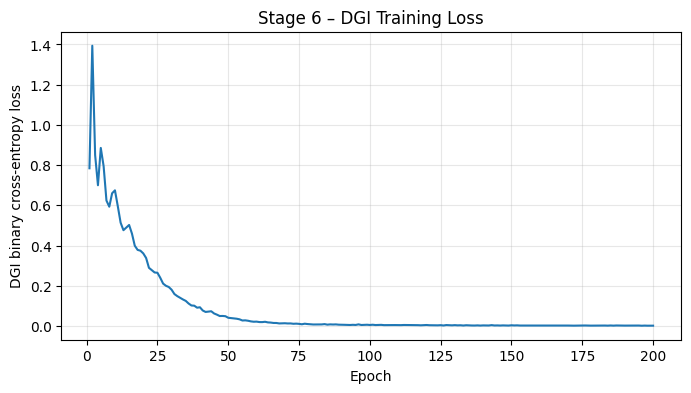

     epoch  dgi_loss
195    196  0.001113
196    197  0.001773
197    198  0.001271
198    199  0.001326
199    200  0.001386


In [13]:
history_df = pd.DataFrame(history)
plt.figure(figsize=(8, 4))
plt.plot(history_df["epoch"], history_df["dgi_loss"])
plt.xlabel("Epoch")
plt.ylabel("DGI binary cross-entropy loss")
plt.title("Stage 6 – DGI Training Loss")
plt.grid(True, alpha=0.3)
plt.show()

print(history_df.tail())

## Step 11 – Extract graph representations

After training, extract the 128-dimensional GCN representations for all nodes. These are graph-aware embeddings and are distinct from the original CNN embeddings.

In [14]:
graph_embeddings = model.get_embeddings(X_torch, A_torch).detach().cpu().numpy().astype(np.float32)
assert graph_embeddings.shape == (N, 128)
assert np.isfinite(graph_embeddings).all()

print("DGI graph embedding shape:", graph_embeddings.shape)
print("Value range:", float(graph_embeddings.min()), "to", float(graph_embeddings.max()))

DGI graph embedding shape: (6400, 128)
Value range: -2.001384973526001 to 2.2493252754211426


## Step 12 – Save outputs and download the Stage 6 report

The output package includes graph embeddings in manifest node order, split indices/masks, training history, configuration, and the trained model checkpoint.

In [15]:
OUTPUT_DIR = Path("/content/Stage6_DGI_Outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

np.savez_compressed(
    OUTPUT_DIR / "stage6_dgi_graph_embeddings.npz",
    graph_embeddings=graph_embeddings,
    train_indices=idx_train,
    val_indices=idx_val,
    test_indices=idx_test,
    train_mask=train_mask,
    val_mask=val_mask,
    test_mask=test_mask,
    labels=labels
)
history_df.to_csv(OUTPUT_DIR / "stage6_dgi_training_history.csv", index=False)
torch.save(model.state_dict(), OUTPUT_DIR / "stage6_dgi_gcn_model.pt")

config = {
    "stage": 6,
    "method": "Deep Graph Infomax with two-layer GCN encoder",
    "input_feature_dimension": int(X.shape[1]),
    "embedding_dimension": 128,
    "nodes": int(N),
    "undirected_edges": int(A.nnz // 2),
    "stage5_knn_k": 10,
    "graph_protocol": "transductive; all node features and graph structure participate in unsupervised DGI training",
    "labels_used_in_dgi_loss": False,
    "gcn_layers": 2,
    "hidden_dimension": 128,
    "dropout": 0.5,
    "optimizer": "Adam",
    "learning_rate": 0.001,
    "weight_decay": 0.0,
    "epochs_run": int(len(history_df)),
    "best_training_loss": float(best_loss),
    "seed": SEED,
    "device": str(DEVICE)
}
with open(OUTPUT_DIR / "stage6_dgi_config.json", "w") as f:
    json.dump(config, f, indent=2)

zip_out = "/content/Stage6_DGI_Outputs.zip"
with zipfile.ZipFile(zip_out, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for p in OUTPUT_DIR.rglob("*"):
        if p.is_file():
            zf.write(p, arcname=p.name)

print("Created:", zip_out)
files.download(zip_out)

Created: /content/Stage6_DGI_Outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 13 – Final checks

After the ZIP download completes, upload `Stage6_DGI_Outputs.zip` in our chat. I will inspect the embeddings, training curve, configuration and checkpoint manifest before preparing Stage 7.

**Please do not proceed to Stage 7 until Stage 6 outputs have been checked.** Also upload this notebook to your private GitHub repository as `Stage6_DGI_GCN_Implementation.ipynb`.